##### Feladat

Határozzuk meg az igénybevételi függvényeket és rajzoljuk fel az igénybevételi ábrákat!

<img src="img/01.jpg" alt="Feladat" width=650px>

##### Csomagok importálása

In [1]:
import numpy as np # Numerikus számítások
import matplotlib.pyplot as plt # Ábrázolás
plt.rcParams['mathtext.fontset'] = 'cm' # Betűtípus az ábrákon
plt.rcParams['font.family'] = 'serif' # Betűtípus az ábrákon
plt.rcParams['font.serif'] = ['cmr10'] # Betűtípus az ábrákon
plt.rcParams['axes.formatter.use_mathtext'] = True # Betűtípus az ábrákon
plt.rcParams['axes.unicode_minus'] = False # Betűtípus az ábrákon
from IPython.display import display, Math, Latex # Szép kimenet Jupyter notebookban
import sympy as sp # Szimbólikus számítások
from sympy import latex # Szép kimenet Jupyter notebookban
sp.init_printing() # Szép kimenet Jupyter notebookban

##### Adatok

In [2]:
L_1 = 2 # m
L_2 = 3 # m
L_3 = 4 # m

F_1 = 8 # kN
F_2 = 7 # kN

M_1 = 4 # kNm
M_2 = 6 # kNm

p_1 = 5 # kN/m

# Rúdirányú koordináta
x = sp.symbols('x')

##### Előjelkonvenció

Az igénybevételek előjelét az alábbi előjelkonvenció szerint határozzuk meg (lásd a 8.1 feladatot):

<img src="img/02.jpg" alt="Feladat" width=300px>

##### Szabadtest ábra

<img src="img/03.jpg" alt="Feladat" width=650px>

* Az $A$ csuklós támaszban két reakcióerő ($A_x$, $A_y$), a $C$ görgős támaszban egy reakcióerő ($C_y$) ébred.

* Az $M_1$ koncentrált nyomaték vektora $z$ irányú (az óramutató járásával ellentétes forgatású) → hajlítónyomatékot okoz.

* Az $M_2$ koncentrált nyomatékok vektora rúdirányú (kettős nyíl): az $A$ pontban $-x$, a $C$ pontban $+x$ irányú → csavarónyomatékot okoznak. Az $x$ tengely körüli nyomatéki egyensúly ($-M_2 + M_2 = 0$) így automatikusan teljesül.

* A megoszló terhelést az egyensúlyi egyenletekben az eredőjével ($F_p = p_1 (L_2 + L_3)$) helyettesítjük, amely a terhelt szakasz felénél, az $A$ ponttól $L_1 + (L_2 + L_3)/2$ távolságra hat.

##### A reakciók

In [3]:
A_x, A_y, C_y = sp.symbols('A_x, A_y, C_y')

##### Egyensúlyi egyenletek

In [4]:
# x irányú erő egyensúly
eq1 = A_x - F_2
display(Math(rf'\sum F_x = 0 \quad \longrightarrow \quad {latex(eq1)} = 0 \qquad (1)'))

# y irányú erő egyensúly
eq2 = A_y - p_1*(L_2 + L_3) + C_y + F_1
display(Math(rf'\sum F_y = 0 \quad \longrightarrow \quad {latex(eq2)} = 0 \qquad (2)'))

# z irányú nyomatéki egyensúly az A pontra
eq3 = M_1 + C_y*(L_1 + L_2) - p_1*(L_2 + L_3)*(L_1 + sp.Rational(L_2 + L_3, 2)) + F_1*(L_1 + L_2 + L_3)
display(Math(rf'\sum M_A = 0 \quad \longrightarrow \quad {latex(eq3)} = 0 \qquad (3)'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Egyensúlyi egyenletek megoldása

In [5]:
sol = sp.solve([eq1, eq2, eq3], [A_x, A_y, C_y])

A_xsol = sol[A_x]
display(Math(rf'A_x = {latex(round(A_xsol, 2))} ~ \mathrm{{kN}}'))

A_ysol = sol[A_y]
display(Math(rf'A_y = {latex(round(A_ysol, 2))} ~ \mathrm{{kN}}'))

C_ysol = sol[C_y]
display(Math(rf'C_y = {latex(round(C_ysol, 2))} ~ \mathrm{{kN}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Szakaszok

* A $B$ pontban kezdődik a megoszló terhelés, a $C$ pontban megjelenik a $C_y$ reakcióerő és az $M_2$ nyomaték → 3 szakasz kell!

* I. szakasz: $x \in [0, L_1]$

* II. szakasz: $x \in [L_1, L_1 + L_2]$

* III. szakasz: $x \in [L_1 + L_2, L_1 + L_2 + L_3]$

<img src="img/04.jpg" alt="Feladat" width=650px>

In [6]:
# A szakaszhatárok x koordinátái
x_B = L_1
x_C = L_1 + L_2
x_D = L_1 + L_2 + L_3

##### Az igénybevételi függvények

Mindhárom szakaszon balról redukálunk, mivel a reakciók már ismertek. A függvények együtthatóit a kiíratásnál 2 tizedesjegyre kerekítjük:

In [7]:
# Az együtthatók kerekítése n tizedesjegyre a kiíratáshoz
# (az evalf() értékes jegyekre kerekít, pl. evalf(3) a 130.5-ből 131-et csinálna)
def kerekit(f, n=2):
    return f.xreplace({c: round(c, n) for c in f.atoms(sp.Number)})

##### I. szakasz: $x \in [0, L_1]$

A $K$ keresztmetszettől balra az $A_x$ és $A_y$ reakcióerők, valamint az $M_1$ és az $A$ pontbeli $M_2$ nyomatékok hatnak.

In [8]:
# Normálerő: az A_x erő jobbra mutat, ami balról nézve negatív
N_1 = -A_xsol
display(Math(rf'N_1(x) = -A_x = {latex(round(N_1, 2))} ~ \mathrm{{kN}}'))

# Nyíróerő: az A_y erő felfelé mutat, ami balról nézve pozitív
V_1 = A_ysol
display(Math(rf'V_1(x) = A_y = {latex(round(V_1, 2))} ~ \mathrm{{kN}}'))

# Hajlítónyomaték: az M_1 nyomaték az óramutató járásával ellentétes (balról nézve pozitív),
# az A_y nyomatéka a K pontra az óramutató járásával megegyező (balról nézve negatív)
M_h1 = M_1 - A_ysol*x
display(Math(rf'M_{{h1}}(x) = M_1 - A_y \cdot x = {latex(kerekit(M_h1))} ~ \mathrm{{kNm}} \qquad \text{{ha }} x ~ [\mathrm{{m}}]'))

# Csavarónyomaték: az A pontbeli M_2 nyomatékvektor -x irányba mutat, ami balról nézve pozitív
M_t1 = M_2
display(Math(rf'M_{{t1}}(x) = M_2 = {latex(M_t1)} ~ \mathrm{{kNm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### II. szakasz: $x \in [L_1, L_1 + L_2]$

A $K$ keresztmetszettől balra az I. szakasz terhelésein kívül a $B$ pont és a $K$ keresztmetszet közötti megoszló terhelés is hat. A megoszló terhelést az eredőjével ($F_p$) helyettesítjük, amely a terhelt szakasz felénél, a $K$ keresztmetszettől $(x - L_1)/2$ távolságra hat.

In [9]:
# A balról elhagyott részen ható megoszló terhelés eredője (F_p-vel helyettesítjük)
F_p = p_1*(x - L_1)
display(Math(rf'F_p = p_1 (x - L_1) = {latex(sp.expand(F_p))} ~ \mathrm{{kN}} \qquad \text{{ha }} x ~ [\mathrm{{m}}]'))

# Normálerő: az A_x erő jobbra mutat, ami balról nézve negatív
N_2 = -A_xsol
display(Math(rf'N_2(x) = -A_x = {latex(round(N_2, 2))} ~ \mathrm{{kN}}'))

# Nyíróerő: az A_y erő felfelé mutat (balról nézve pozitív), az F_p erő lefelé mutat (balról nézve negatív)
V_2 = sp.expand(A_ysol - F_p)
display(Math(rf'V_2(x) = A_y - p_1 (x - L_1) = {latex(kerekit(V_2))} ~ \mathrm{{kN}} \qquad \text{{ha }} x ~ [\mathrm{{m}}]'))

# Hajlítónyomaték: az M_1 nyomaték az óramutató járásával ellentétes (balról nézve pozitív),
# az A_y nyomatéka a K pontra az óramutató járásával megegyező (balról nézve negatív),
# az F_p nyomatéka (erőkar: (x - L_1)/2) az óramutató járásával ellentétes (balról nézve pozitív)
M_h2 = sp.expand(M_1 - A_ysol*x + F_p*(x - L_1)/2)
display(Math(rf'M_{{h2}}(x) = M_1 - A_y \cdot x + p_1 \frac{{(x - L_1)^2}}{{2}} = {latex(kerekit(M_h2))} ~ \mathrm{{kNm}} \qquad \text{{ha }} x ~ [\mathrm{{m}}]'))

# Csavarónyomaték: az A pontbeli M_2 nyomatékvektor -x irányba mutat, ami balról nézve pozitív
M_t2 = M_2
display(Math(rf'M_{{t2}}(x) = M_2 = {latex(M_t2)} ~ \mathrm{{kNm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### III. szakasz: $x \in [L_1 + L_2, L_1 + L_2 + L_3]$

A $K$ keresztmetszettől balra a II. szakasz terhelésein kívül a $C_y$ reakcióerő és a $C$ pontbeli $M_2$ nyomaték is hat. A megoszló terhelés eredője ugyanaz, mint a II. szakaszon.

In [10]:
# Normálerő: az A_x erő jobbra mutat, ami balról nézve negatív
N_3 = -A_xsol
display(Math(rf'N_3(x) = -A_x = {latex(round(N_3, 2))} ~ \mathrm{{kN}}'))

# Nyíróerő: az A_y és a C_y erő felfelé mutat (balról nézve pozitív), az F_p erő lefelé mutat (balról nézve negatív)
V_3 = sp.expand(A_ysol - F_p + C_ysol)
display(Math(rf'V_3(x) = A_y - p_1 (x - L_1) + C_y = {latex(kerekit(V_3))} ~ \mathrm{{kN}} \qquad \text{{ha }} x ~ [\mathrm{{m}}]'))

# Hajlítónyomaték: a II. szakasz tagjain kívül a C_y nyomatéka a K pontra az óramutató járásával megegyező (balról nézve negatív)
M_h3 = sp.expand(M_1 - A_ysol*x + F_p*(x - L_1)/2 - C_ysol*(x - L_1 - L_2))
display(Math(rf'M_{{h3}}(x) = M_1 - A_y \cdot x + p_1 \frac{{(x - L_1)^2}}{{2}} - C_y (x - L_1 - L_2) = {latex(kerekit(M_h3))} ~ \mathrm{{kNm}} \qquad \text{{ha }} x ~ [\mathrm{{m}}]'))

# Csavarónyomaték: az A pontbeli M_2 nyomatékvektor -x irányba mutat (balról nézve pozitív),
# a C pontbeli M_2 nyomatékvektor +x irányba mutat (balról nézve negatív)
M_t3 = M_2 - M_2
display(Math(rf'M_{{t3}}(x) = M_2 - M_2 = {latex(M_t3)} ~ \mathrm{{kNm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Ellenőrzés

* A hajlítónyomaték a szakaszhatárokon ($x = L_1$ és $x = L_1 + L_2$) folytonos, mert ott nem hat $z$ irányú koncentrált nyomaték.

* A nyíróerő a $C$ pontban a $C_y$ reakcióerővel ugrik.

* A $D$ pontban (a tartó jobb végén) jobbról csak az $F_1$ és $F_2$ erők hatnak, így ott: $N = -F_2$, $V = -F_1$ és $M_h = 0$.

In [11]:
# A hajlítónyomaték a szakaszhatárokon mindkét szakasz függvényéből
display(Math(rf'M_{{h1}}(x=L_1) = {latex(round(M_h1.subs(x, x_B), 2))} ~ \mathrm{{kNm}} \qquad M_{{h2}}(x=L_1) = {latex(round(M_h2.subs(x, x_B), 2))} ~ \mathrm{{kNm}}'))
display(Math(rf'M_{{h2}}(x=L_1+L_2) = {latex(round(M_h2.subs(x, x_C), 2))} ~ \mathrm{{kNm}} \qquad M_{{h3}}(x=L_1+L_2) = {latex(round(M_h3.subs(x, x_C), 2))} ~ \mathrm{{kNm}}'))

# A nyíróerő ugrása a C pontban
display(Math(rf'V_3(x=L_1+L_2) - V_2(x=L_1+L_2) = {latex(round(V_3.subs(x, x_C) - V_2.subs(x, x_C), 2))} ~ \mathrm{{kN}} \qquad C_y = {latex(round(C_ysol, 2))} ~ \mathrm{{kN}}'))

# Az igénybevételek a D pontban
display(Math(rf'N_3(x=L_1+L_2+L_3) = {latex(round(N_3, 2))} ~ \mathrm{{kN}} \qquad -F_2 = {latex(-F_2)} ~ \mathrm{{kN}}'))
display(Math(rf'V_3(x=L_1+L_2+L_3) = {latex(round(V_3.subs(x, x_D), 2))} ~ \mathrm{{kN}} \qquad -F_1 = {latex(-F_1)} ~ \mathrm{{kN}}'))
display(Math(rf'M_{{h3}}(x=L_1+L_2+L_3) = {latex(round(M_h3.subs(x, x_D), 2))} ~ \mathrm{{kNm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Derivált kapcsolatok: $V'(x) = p(x)$ és $M_h'(x) = -V(x)$ mindhárom szakaszon.

Az I. szakaszon nincs megoszló terhelés, a II. és III. szakaszon a megoszló terhelés lefelé ($-y$ irányba) mutat, így $p(x) = -p_1$.

In [12]:
# A megoszló terhelés függvénye szakaszonként
p_x1 = 0
p_x2 = -p_1
p_x3 = -p_1

# A nyíróerő deriváltjai
display(Math(rf"V_1'(x) = {latex(sp.diff(V_1, x))} \qquad p(x) = {latex(p_x1)}"))
display(Math(rf"V_2'(x) = {latex(sp.diff(V_2, x))} \qquad p(x) = {latex(p_x2)}"))
display(Math(rf"V_3'(x) = {latex(sp.diff(V_3, x))} \qquad p(x) = {latex(p_x3)}"))

# A hajlítónyomaték deriváltjai
display(Math(rf"M_{{h1}}'(x) = {latex(kerekit(sp.diff(M_h1, x)))} \qquad -V_1(x) = {latex(kerekit(-V_1))}"))
display(Math(rf"M_{{h2}}'(x) = {latex(kerekit(sp.diff(M_h2, x)))} \qquad -V_2(x) = {latex(kerekit(-V_2))}"))
display(Math(rf"M_{{h3}}'(x) = {latex(kerekit(sp.diff(M_h3, x)))} \qquad -V_3(x) = {latex(kerekit(-V_3))}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Látható, hogy az összefüggések teljesülnek.

##### Ábrázolás

* $N(x)$ és $M_t(x)$: szakaszonként konstans.

* $V(x)$: szakaszonként lineáris, szakaszonként 2 pontot kiszámolunk, behúzzuk.

* $M_h(x)$: az I. szakaszon lineáris, a II. és III. szakaszon parabola, szerkeszteni kell.

In [13]:
# A nyíróerő a szakaszhatárokon
display(Math(rf'V_1(x=0) = {latex(round(V_1, 2))} ~ \mathrm{{kN}} \qquad V_1(x=L_1) = {latex(round(V_1, 2))} ~ \mathrm{{kN}}'))
display(Math(rf'V_2(x=L_1) = {latex(round(V_2.subs(x, x_B), 2))} ~ \mathrm{{kN}} \qquad V_2(x=L_1+L_2) = {latex(round(V_2.subs(x, x_C), 2))} ~ \mathrm{{kN}}'))
display(Math(rf'V_3(x=L_1+L_2) = {latex(round(V_3.subs(x, x_C), 2))} ~ \mathrm{{kN}} \qquad V_3(x=L_1+L_2+L_3) = {latex(round(V_3.subs(x, x_D), 2))} ~ \mathrm{{kN}}'))

# A hajlítónyomaték a szakaszhatárokon
display(Math(rf'M_{{h1}}(x=0) = {latex(round(M_h1.subs(x, 0), 2))} ~ \mathrm{{kNm}} \qquad M_{{h1}}(x=L_1) = {latex(round(M_h1.subs(x, x_B), 2))} ~ \mathrm{{kNm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### A parabolák szerkesztése

A szerkesztés lépései (lásd a 8.6 feladatot), a II. és a III. szakaszon külön-külön:

1. $V(x)$ felrajzolása, segédvonal a lineáris $V(x)$ tartomány felénél
2. $M_h(x)$ kezdő- és végpontbeli értékének felrajzolása
3. $M_h(x)$ kezdő- és végpontbeli érintőinek berajzolása
4. érintők metszéspontjának kiszámítása: $P$ pont
5. húzzuk be a húrt a kezdő- és a végpont közé → $Q$ pont: a húr szakasz felénél lévő pontja
6. felezzük meg a $PQ$ szakaszt: a szakasz felezőpontja az $S$ pont
7. húzzunk párhuzamost a húrral, $S$ ponton keresztül → ez a parabola érintője $S$ pontban
8. rajzoljuk meg a parabolát!

A $P$ pont helye: a kezdőpontbeli érintő a tartomány felén $M_h'(x_0) \cdot \Delta x/2 = -V(x_0) \cdot \Delta x/2$ értékkel változik ($\Delta x$: a szakasz hossza) → $M_h(x)$ kezdőértékéből vonjuk le a $V(x)$ ábrán berajzolt téglalap területét ($A_1$, ill. $A_2$)!

In [14]:
def parabola_szerkesztes(M_h, V, x_0, x_1):
    # 1.) Segédvonal a lineáris V(x) tartomány felénél
    x_F = sp.Rational(x_0 + x_1, 2)
    # 2.) M_h(x) kezdő- és végpontbeli értéke
    M_hk = M_h.subs(x, x_0)
    M_hv = M_h.subs(x, x_1)
    # 3.) M_h(x) kezdő- és végpontbeli érintőinek meredeksége: M_h'(x) = -V(x)
    m_k = -V.subs(x, x_0)
    m_v = -V.subs(x, x_1)
    # 4.) A téglalap területe a V(x) ábrán (a tartomány első felén), az érintők metszéspontja: P pont
    A = V.subs(x, x_0)*(x_F - x_0)
    r_P = sp.Matrix([x_F, M_hk - A])
    # 5.) A húr a kezdő- és a végpont között, Q pont: a húr szakasz felénél lévő pontja
    r_Q = sp.Matrix([x_F, (M_hk + M_hv)/2])
    # 6.) A PQ szakasz felezőpontja: S pont
    r_S = (r_P + r_Q)/2
    # 7.) A húr meredeksége (az S pontbeli érintő ezzel párhuzamos)
    m_hur = (M_hv - M_hk)/(x_1 - x_0)
    return {'x_F': x_F, 'M_hk': M_hk, 'M_hv': M_hv, 'm_k': m_k, 'm_v': m_v, 'A': A, 'P': r_P, 'Q': r_Q, 'S': r_S, 'm_hur': m_hur}

##### II. szakasz: $x \in [L_1, L_1 + L_2]$

In [15]:
sz2 = parabola_szerkesztes(M_h2, V_2, x_B, x_C)

# 1.) Segédvonal a szakasz felénél
display(Math(rf'x_F = L_1 + \frac{{L_2}}{{2}} = {latex(round(sz2["x_F"], 2))} ~ \mathrm{{m}}'))

# 2.) M_h(x) kezdő- és végpontbeli értéke
display(Math(rf'M_{{h2}}(x=L_1) = {latex(round(sz2["M_hk"], 2))} ~ \mathrm{{kNm}} \qquad M_{{h2}}(x=L_1+L_2) = {latex(round(sz2["M_hv"], 2))} ~ \mathrm{{kNm}}'))

# 3.) M_h(x) kezdő- és végpontbeli érintőinek meredeksége
display(Math(rf"M_{{h2}}'(x=L_1) = -V_2(x=L_1) = {latex(round(sz2['m_k'], 2))} \qquad M_{{h2}}'(x=L_1+L_2) = -V_2(x=L_1+L_2) = {latex(round(sz2['m_v'], 2))}"))

# 4.) Az A_1 téglalap és az érintők metszéspontja: P pont
display(Math(rf'A_1 = V_2(x=L_1) \cdot \frac{{L_2}}{{2}} = {latex(round(sz2["A"], 2))} ~ \mathrm{{kNm}}'))
display(Math(rf'P = {latex(kerekit(sz2["P"]))}'))

# Ellenőrzés: a végpontból is ugyanazt kapjuk
display(Math(rf'M_{{h2}}(x=L_1+L_2) + V_2(x=L_1+L_2) \cdot \frac{{L_2}}{{2}} = {latex(round(sz2["M_hv"] + V_2.subs(x, x_C)*sp.Rational(L_2, 2), 2))} ~ \mathrm{{kNm}}'))

# 5.) Q pont és 6.) S pont
display(Math(rf'Q = {latex(kerekit(sz2["Q"]))} \qquad S = {latex(kerekit(sz2["S"], 3))}'))

# 7.) A húr meredeksége
display(Math(rf'm_{{\text{{húr}}}} = {latex(round(sz2["m_hur"], 2))}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### III. szakasz: $x \in [L_1 + L_2, L_1 + L_2 + L_3]$

In [16]:
sz3 = parabola_szerkesztes(M_h3, V_3, x_C, x_D)

# 1.) Segédvonal a szakasz felénél
display(Math(rf'x_F = L_1 + L_2 + \frac{{L_3}}{{2}} = {latex(round(sz3["x_F"], 2))} ~ \mathrm{{m}}'))

# 2.) M_h(x) kezdő- és végpontbeli értéke
display(Math(rf'M_{{h3}}(x=L_1+L_2) = {latex(round(sz3["M_hk"], 2))} ~ \mathrm{{kNm}} \qquad M_{{h3}}(x=L_1+L_2+L_3) = {latex(round(sz3["M_hv"], 2))} ~ \mathrm{{kNm}}'))

# 3.) M_h(x) kezdő- és végpontbeli érintőinek meredeksége
display(Math(rf"M_{{h3}}'(x=L_1+L_2) = -V_3(x=L_1+L_2) = {latex(round(sz3['m_k'], 2))} \qquad M_{{h3}}'(x=L_1+L_2+L_3) = -V_3(x=L_1+L_2+L_3) = {latex(round(sz3['m_v'], 2))}"))

# 4.) Az A_2 téglalap és az érintők metszéspontja: P pont
display(Math(rf'A_2 = V_3(x=L_1+L_2) \cdot \frac{{L_3}}{{2}} = {latex(round(sz3["A"], 2))} ~ \mathrm{{kNm}}'))
display(Math(rf'P = {latex(kerekit(sz3["P"]))}'))

# Ellenőrzés: a végpontból is ugyanazt kapjuk
display(Math(rf'M_{{h3}}(x=L_1+L_2+L_3) + V_3(x=L_1+L_2+L_3) \cdot \frac{{L_3}}{{2}} = {latex(round(sz3["M_hv"] + V_3.subs(x, x_D)*sp.Rational(L_3, 2), 2))} ~ \mathrm{{kNm}}'))

# 5.) Q pont és 6.) S pont
display(Math(rf'Q = {latex(kerekit(sz3["Q"]))} \qquad S = {latex(kerekit(sz3["S"], 3))}'))

# 7.) A húr meredeksége
display(Math(rf'm_{{\text{{húr}}}} = {latex(round(sz3["m_hur"], 2))}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Ellenőrzés: az $S$ pontok rajta vannak a parabolákon:

In [17]:
display(Math(rf'M_{{h2}}(x={latex(round(sz2["x_F"], 2))}) = {latex(round(M_h2.subs(x, sz2["x_F"]), 3))} ~ \mathrm{{kNm}}'))
display(Math(rf'M_{{h3}}(x={latex(round(sz3["x_F"], 2))}) = {latex(round(M_h3.subs(x, sz3["x_F"]), 3))} ~ \mathrm{{kNm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Szélsőértékek

Ahol $V(x) = 0$, ott $M_h(x)$-nek szélsőértéke van (vízszintes érintő). A $V(x)$ függvény a II. szakaszon ($x_1$) és a III. szakaszon ($x_2$) is előjelet vált.

In [18]:
# II. szakasz: V_2(x) = 0
x_1 = sp.solve(V_2, x)[0]
display(Math(rf'V_2(x) = 0 \quad \longrightarrow \quad x_1 = {latex(round(x_1, 2))} ~ \mathrm{{m}}'))

M_hsz1 = M_h2.subs(x, x_1)
display(Math(rf'M_{{h2}}(x_1) = {latex(round(M_hsz1, 2))} ~ \mathrm{{kNm}}'))

# III. szakasz: V_3(x) = 0
x_2 = sp.solve(V_3, x)[0]
display(Math(rf'V_3(x) = 0 \quad \longrightarrow \quad x_2 = {latex(round(x_2, 2))} ~ \mathrm{{m}}'))

M_hsz2 = M_h3.subs(x, x_2)
display(Math(rf'M_{{h3}}(x_2) = {latex(round(M_hsz2, 2))} ~ \mathrm{{kNm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Mindkét szélsőérték helye a saját szakaszán belül van ($L_1 \leq x_1 \leq L_1 + L_2$ és $L_1 + L_2 \leq x_2 \leq L_1 + L_2 + L_3$).

##### Az igénybevételi ábrák

In [19]:
def igenybeveteli_abra(ax, f, x_0, x_1, felirat, szin='red'):
    # A függvény kiértékelése numerikusan az [x_0, x_1] tartományon
    x_vals = np.linspace(x_0, x_1, 201)
    f_vals = sp.lambdify(x, f, 'numpy')(x_vals) * np.ones_like(x_vals) # Konstans függvény esetén is tömböt kapunk
    # A függvény görbéje (zorder: az x tengely fölé rajzoljuk)
    ax.plot(x_vals, f_vals, color=szin, lw=1.5, zorder=3)
    # Satírozás a görbe és az x tengely között (mint a kézi rajzokon)
    ax.vlines(x_vals[::10], 0, f_vals[::10], color=szin, lw=0.8)
    # Lezárás a tartomány két végén
    ax.vlines([x_0, x_1], 0, [f_vals[0], f_vals[-1]], color=szin, lw=1.5, zorder=3)
    # Az x tengely
    ax.axhline(0, color='black', lw=1)
    ax.set_ylabel(felirat)
    ax.grid(True, alpha=0.5)

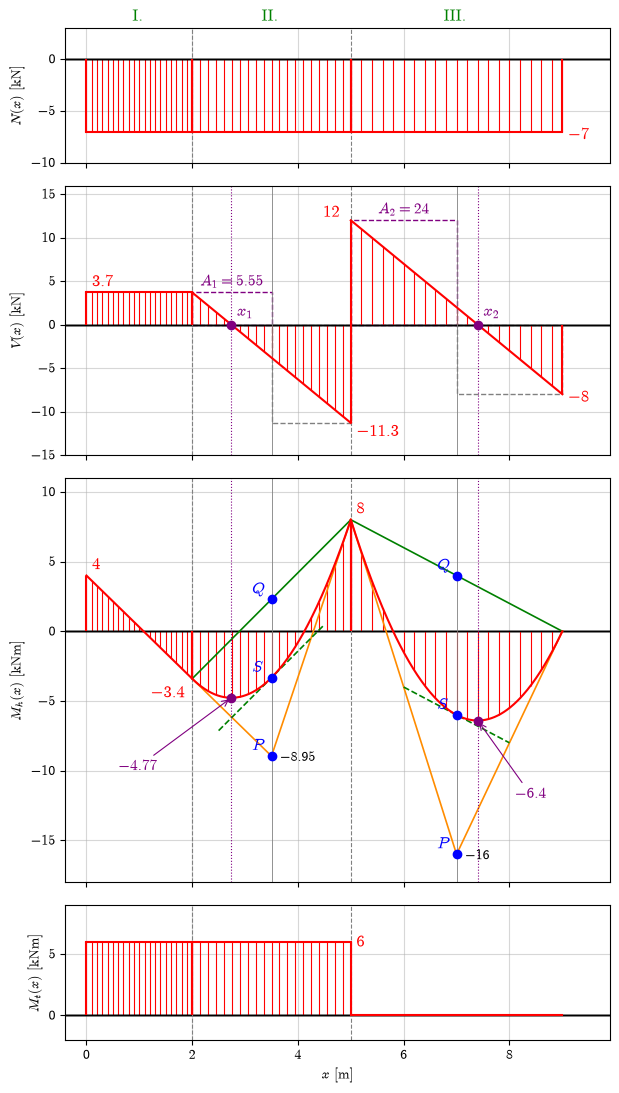

In [20]:
fig, axs = plt.subplots(4, 1, figsize=(16/2.54, 28/2.54), sharex=True, gridspec_kw={'height_ratios': [1, 2, 3, 1]})

# A szakaszok jelölése (mint a kézi rajzon)
for nev, x_m in zip(['I.', 'II.', 'III.'], [x_B/2, (x_B + x_C)/2, (x_C + x_D)/2]):
    axs[0].text(x_m, 1.05, rf'$\mathrm{{{nev}}}$', transform=axs[0].get_xaxis_transform(), ha='center', color='green', fontsize=12)

# N(x)
igenybeveteli_abra(axs[0], N_1, 0, x_B, r'$N(x) ~ [\mathrm{kN}]$')
igenybeveteli_abra(axs[0], N_2, x_B, x_C, r'$N(x) ~ [\mathrm{kN}]$')
igenybeveteli_abra(axs[0], N_3, x_C, x_D, r'$N(x) ~ [\mathrm{kN}]$')
axs[0].annotate(rf'${latex(round(N_3, 2))}$', xy=(x_D, float(N_3)), xytext=(4, -6), textcoords='offset points', color='red', fontsize=12)
axs[0].set_ylim(-10, 3)

# V(x)
igenybeveteli_abra(axs[1], V_1, 0, x_B, r'$V(x) ~ [\mathrm{kN}]$')
igenybeveteli_abra(axs[1], V_2, x_B, x_C, r'$V(x) ~ [\mathrm{kN}]$')
igenybeveteli_abra(axs[1], V_3, x_C, x_D, r'$V(x) ~ [\mathrm{kN}]$')
axs[1].annotate(rf'${latex(round(V_1, 2))}$', xy=(0, float(V_1)), xytext=(4, 4), textcoords='offset points', color='red', fontsize=12)
axs[1].annotate(rf'${latex(round(V_2.subs(x, x_C), 2))}$', xy=(x_C, float(V_2.subs(x, x_C))), xytext=(4, -10), textcoords='offset points', color='red', fontsize=12)
axs[1].annotate(rf'${latex(round(V_3.subs(x, x_C), 2))}$', xy=(x_C, float(V_3.subs(x, x_C))), xytext=(-20, 2), textcoords='offset points', color='red', fontsize=12)
axs[1].annotate(rf'${latex(round(V_3.subs(x, x_D), 2))}$', xy=(x_D, float(V_3.subs(x, x_D))), xytext=(4, -6), textcoords='offset points', color='red', fontsize=12)

# 4.) Az A_1 és A_2 téglalapok (és a szakaszok második felén a végpontbeli téglalapok)
for sz, x_0, x_1v, V_f, nev in [(sz2, x_B, x_C, V_2, 'A_1'), (sz3, x_C, x_D, V_3, 'A_2')]:
    x_F = float(sz['x_F'])
    axs[1].add_patch(plt.Rectangle((x_0, 0), x_F - x_0, float(V_f.subs(x, x_0)), fill=False, ls='--', color='purple'))
    axs[1].add_patch(plt.Rectangle((x_F, 0), x_1v - x_F, float(V_f.subs(x, x_1v)), fill=False, ls='--', color='gray'))
    axs[1].annotate(rf'${nev} = {latex(round(sz["A"], 2))}$', xy=((x_0 + x_F)/2, float(V_f.subs(x, x_0))), xytext=(0, 5), textcoords='offset points', ha='center', color='purple', fontsize=11)

# A V(x) = 0 helyek: x_1 és x_2
for x_sz, nev in [(x_1, 'x_1'), (x_2, 'x_2')]:
    axs[1].plot(float(x_sz), 0, 'o', color='purple', zorder=10)
    axs[1].annotate(rf'${nev}$', xy=(float(x_sz), 0), xytext=(4, 6), textcoords='offset points', color='purple', fontsize=12)
axs[1].set_ylim(-15, 16)

# M_h(x)
igenybeveteli_abra(axs[2], M_h1, 0, x_B, r'$M_h(x) ~ [\mathrm{kNm}]$')
igenybeveteli_abra(axs[2], M_h2, x_B, x_C, r'$M_h(x) ~ [\mathrm{kNm}]$')
igenybeveteli_abra(axs[2], M_h3, x_C, x_D, r'$M_h(x) ~ [\mathrm{kNm}]$')
axs[2].annotate(rf'${latex(round(M_h1.subs(x, 0), 2))}$', xy=(0, float(M_h1.subs(x, 0))), xytext=(4, 4), textcoords='offset points', color='red', fontsize=12)
axs[2].annotate(rf'${latex(round(M_h1.subs(x, x_B), 2))}$', xy=(x_B, float(M_h1.subs(x, x_B))), xytext=(-30, -14), textcoords='offset points', color='red', fontsize=12)
axs[2].annotate(rf'${latex(round(M_h2.subs(x, x_C), 2))}$', xy=(x_C, float(M_h2.subs(x, x_C))), xytext=(4, 4), textcoords='offset points', color='red', fontsize=12)

# A parabolák szerkesztése a II. és III. szakaszon
for sz, x_0, x_1v in [(sz2, x_B, x_C), (sz3, x_C, x_D)]:
    P_v = np.array(sz['P'], dtype=float).flatten()
    Q_v = np.array(sz['Q'], dtype=float).flatten()
    S_v = np.array(sz['S'], dtype=float).flatten()
    # 3.) Érintők a kezdő- és végpontban, 4.) metszéspontjuk a P pont
    axs[2].plot([x_0, P_v[0], x_1v], [float(sz['M_hk']), P_v[1], float(sz['M_hv'])], color='darkorange', lw=1.2)
    # 5.) Húr
    axs[2].plot([x_0, x_1v], [float(sz['M_hk']), float(sz['M_hv'])], color='green', lw=1.2)
    # 7.) Érintő az S pontban (párhuzamos a húrral)
    x_e = np.array([S_v[0] - 1, S_v[0] + 1])
    axs[2].plot(x_e, S_v[1] + float(sz['m_hur'])*(x_e - S_v[0]), color='green', ls='--', lw=1.2)
    # 4.), 5.), 6.) P, Q és S pontok (zorder: minden más fölé rajzoljuk)
    for nev, r_v in zip(['P', 'Q', 'S'], [P_v, Q_v, S_v]):
        axs[2].plot(r_v[0], r_v[1], 'o', color='blue', zorder=10)
        axs[2].annotate(rf'${nev}$', xy=r_v, xytext=(-14, 4), textcoords='offset points', color='blue', fontsize=12, zorder=10)
    # A P pont értéke
    axs[2].annotate(rf'${latex(round(sz["P"][1], 2))}$', xy=P_v, xytext=(6, -4), textcoords='offset points', color='black', fontsize=10)

# A szélsőértékek (a feliratot nyíllal a szerkesztési vonalaktól távolabb helyezzük el)
for x_sz, M_sz, r_felirat in [(x_1, M_hsz1, (0.6, -10)), (x_2, M_hsz2, (8.1, -12))]:
    axs[2].plot(float(x_sz), float(M_sz), 'o', color='purple', zorder=10)
    axs[2].annotate(rf'${latex(round(M_sz, 2))}$', xy=(float(x_sz), float(M_sz)), xytext=r_felirat, color='purple', fontsize=11,
                    arrowprops=dict(arrowstyle='->', color='purple', lw=0.8))
axs[2].set_ylim(-18, 11)

# M_t(x)
igenybeveteli_abra(axs[3], M_t1, 0, x_B, r'$M_t(x) ~ [\mathrm{kNm}]$')
igenybeveteli_abra(axs[3], M_t2, x_B, x_C, r'$M_t(x) ~ [\mathrm{kNm}]$')
igenybeveteli_abra(axs[3], M_t3, x_C, x_D, r'$M_t(x) ~ [\mathrm{kNm}]$')
axs[3].annotate(rf'${latex(M_t2)}$', xy=(x_C, float(M_t2)), xytext=(4, -4), textcoords='offset points', color='red', fontsize=12)
axs[3].set_ylim(-2, 9)

# Segédvonalak: szakaszhatárok, a szakaszok fele és a szélsőértékek helye
for ax in axs:
    for x_h in [x_B, x_C]:
        ax.axvline(x_h, color='gray', ls='--', lw=0.8)
for ax in axs[1:3]:
    for sz in [sz2, sz3]:
        ax.axvline(float(sz['x_F']), color='gray', ls='-', lw=0.6)
    for x_sz in [x_1, x_2]:
        ax.axvline(float(x_sz), color='purple', ls=':', lw=0.8)

axs[3].set_xlim(-0.4, x_D + 0.9)
axs[3].set_xlabel(r'$x ~ [\mathrm{m}]$')
plt.tight_layout()
plt.savefig('igenybeveteli_fuggvenyek.pdf') # Az ábra mentése PDF dokumentumba
plt.show()

A hajlítónyomaték abszolút értékben legnagyobb értéke a jellemző értékek (szakaszhatárok, szélsőértékek) közül:

In [21]:
# A hajlítónyomaték jellemző értékei: a szakaszhatárokon és a szélsőértékeknél
M_h_ertekek = [M_h1.subs(x, 0), M_h1.subs(x, x_B), M_h2.subs(x, x_C), M_hsz1, M_hsz2, M_h3.subs(x, x_D)]
display(Math(rf'|M_h|_{{max}} = {latex(round(max(abs(v) for v in M_h_ertekek), 2))} ~ \mathrm{{kNm}}'))

<IPython.core.display.Math object>

Ez a $C$ támasz felett ($x = L_1 + L_2$) ébred.